# Mapas autoorganizados de Kohonen (SOM)

Implementación desde cero de un *Self-Organizing Map* sobre dos conjuntos de datos:
`data/breast.txt` (699 muestras celulares, 9 atributos) y `data/cars.xls` (38
vehículos, 6 atributos numéricos). Se cubren la selección de la BMU, la función de
vecindad gaussiana, la actualización de pesos con agenda de decaimiento, las métricas
de cuantización (QE) y topología (TE), y las visualizaciones estándar del mapa:
U-matrix, hit map, cluster map y component planes.

La red es propia: numpy se usa para el cálculo vectorial, pandas y matplotlib para
datos y gráficos, y python-calamine para leer el archivo `.xls`. Requisitos: Python
3.10 o superior. Todo el cuaderno corre con la semilla fija 42, de modo que los
resultados son reproducibles.

## 1. Alcance y aplicabilidad

El mapa autoorganizado de Kohonen (SOM, *Self-Organizing Map*) es una red neuronal de
aprendizaje no supervisado que proyecta datos de alta dimensión sobre una grilla
bidimensional de neuronas preservando la vecindad: patrones cercanos en el espacio
original activan neuronas cercanas en el mapa. Cada neurona tiene un vector de pesos
de la misma dimensión que los datos, y el entrenamiento es competitivo y cooperativo:
una neurona gana (BMU) y sus vecinas se acercan al patrón junto con ella.

### Cuándo conviene usar un SOM

- Exploración de datos sin etiquetas: se quiere ver la estructura de agrupamiento
  cuando no se conocen ni el número ni la forma de los grupos.
- Reducción de dimensionalidad visual: llevar 9, 20 o más atributos a un mapa 2D
  legible sin perder la relación de vecindad entre observaciones.
- Cuantización vectorial: los pesos de las neuronas funcionan como prototipos
  (centroides) que representan las regiones densas del espacio de datos.
- Segmentación: separar poblaciones difusas (clientes, perfiles, regiones del mapa de
  características) para análisis posteriores.
- Códigos y mapas de características: cuando interesa la organización interna de los
  datos, no sólo una etiqueta por instancia.

Casos donde el SOM no es la herramienta adecuada:

- Se necesitan fronteras duras y reglas explícitas de decisión: k-means o árboles
  ofrecen eso directamente; el SOM da organización, no clasificación.
- Se requiere incertidumbre cuantificada o inferencia: un SOM no produce
  probabilidades.
- Muy pocos patrones respecto de la dimensionalidad: el mapa sobreajusta y la
  preservación topológica se degrada (el topographic error lo detecta).
- Se exige determinismo sin control: el entrenamiento es estocástico; con semilla
  fija es reproducible, sin ella sólo se pueden reportar tendencias.

### Qué información entrega el modelo

Además del mapa en sí, el SOM produce: la U-matrix, que revela fronteras y zonas de
transición entre agrupamientos; el hit map, con la densidad de asignaciones por
neurona y la detección de neuronas muertas; los component planes, un mapa por atributo
que muestra qué característica domina cada zona; los prototipos (los pesos como
centroides cuantizados del dataset); y dos métricas de calidad: el quantization error
(cuéntan bien se representan los datos) y el topographic error (cuánto se preserva la
estructura).

## 2. Marco teórico

### Neurona y Best Matching Unit

Cada neurona $i$ de la grilla tiene un vector de pesos
$W_i = (w_{i1}, \ldots, w_{in})$ con la misma dimensión que los datos. Para un patrón
de entrada $X$, la neurona ganadora es la de menor distancia euclídea:

$$\mathrm{BMU} = \arg\min_i \| X - W_i \|, \qquad
d(X, W_i) = \sqrt{\sum_{j=1}^{n} (x_j - w_{ij})^2}$$

### Función de vecindad

El entrenamiento es cooperativo: además de la BMU se actualizan las neuronas cercanas
en la grilla, con un peso que decae con la distancia en la retícula:

$$h_{ci}(t) = \exp\left(-\frac{d_{\mathrm{grid}}(c, i)^2}{2\,\sigma(t)^2}\right)$$

donde $c$ es la BMU, $d_{\mathrm{grid}}$ es la distancia Manhattan sobre la retícula y
$\sigma(t)$ es el radio de vecindad.

### Actualización de pesos

$$W_i(t+1) = W_i(t) + \alpha(t)\, h_{ci}(t)\, \bigl(X - W_i(t)\bigr)$$

La tasa de aprendizaje $\alpha(t)$ y el radio $\sigma(t)$ decaen con el tiempo. En este
cuaderno se usan agendas lineales:

$$\alpha(t) = \alpha_0 \left(1 - \frac{t}{T}\right), \qquad
\sigma(t) = \max\left(\sigma_{\min},\; \sigma_0 \left(1 - \frac{t}{T}\right)\right), \quad
\sigma_0 = \frac{\max(\text{filas}, \text{columnas})}{2}$$

El suelo $\sigma_{\min} = 1$ mantiene como mínimo la cooperación entre vecinas
inmediatas durante todo el entrenamiento. Sin ese suelo, las últimas épocas actualizan
neuronas aisladas, el mapa se pliega y el topographic error sube: es el trade-off
cuantización-topología, medido en la sección 7.

### Normalización

Antes de entrenar, cada atributo se escala a $[0, 1]$:

$$X' = \frac{X - X_{\min}}{X_{\max} - X_{\min}}$$

Sin normalización, la distancia euclídea la dominan los atributos de mayor rango
numérico y el resto de las dimensiones quedan sin efecto.

### Métricas de evaluación

Quantization error — distancia media entre cada patrón y su BMU:

$$QE = \frac{1}{N} \sum_{k=1}^{N} \| X_k - W_{\mathrm{BMU}(k)} \|$$

Topographic error — fracción de patrones cuya primera y segunda BMU no son vecinas en
la grilla:

$$TE = \frac{1}{N} \sum_{k=1}^{N} \mathbb{1}\bigl[\mathrm{BMU}_1(k) \text{ y }
\mathrm{BMU}_2(k) \text{ no adyacentes}\bigr]$$

Un QE menor indica mejor representación; un TE cercano a cero indica que la vecindad
del espacio de datos se preservó en el mapa.

### Supuestos

1. Los atributos se normalizan min-max por columna. Es un supuesto crítico: sin él, la
   distancia euclídea responde al atributo de mayor escala.
2. La similitud entre patrones se mide con distancia euclídea en el espacio
   normalizado, y la cooperación con distancia Manhattan sobre la retícula.
3. La grilla es rectangular y topológicamente regular; la vecindad es un kernel
   gaussiano sobre esa retícula.
4. El orden de presentación se aleatoriza en cada época; la estocasticidad queda
   fijada con la semilla 42.
5. Los pesos se inicializan con patrones elegidos al azar del dataset, de modo que
   arrancan dentro del soporte de los datos.
6. El SOM no asigna etiquetas: los grupos se leen por zonas de la grilla y se evalúan
   contra las clases externas sólo con fines de análisis.
7. QE y TE se miden en el espacio normalizado: sólo son comparables entre
   experimentos que usan la misma normalización y el mismo espacio de atributos.

### Costo computacional

Por época, la búsqueda de la BMU cuesta $O(N \cdot M \cdot D)$ y las actualizaciones
otro tanto, donde $N$ es la cantidad de patrones, $M$ la de neuronas y $D$ la
dimensión. El entrenamiento completo cuesta $O(T \cdot N \cdot M \cdot D)$. Para
breast: $200 \times 699 \times 100 \times 9$ operaciones escalares, resueltas con
álgebra matricial de numpy en unos segundos.

In [1]:
import itertools
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

SEMILLA = 42

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

## 3. Conjuntos de datos

`breast.txt` es el conjunto Wisconsin de diagnóstico de tumores de mama: 699 muestras
celulares con 9 atributos numéricos evaluados en una escala de 1 a 10 y una clase
(`begnin` con 458 instancias y `malignant` con 241; la grafía de la clase se mantiene
igual que en el archivo). Las clases se usan sólo para colorear el cluster map: el
entrenamiento no las ve.

| Atributo / Variable | Valores / Escala | Rol |
|---|---|---|
| clump, ucellsize, ucellshape | Enteros [1, 10] | predictivo / entrenamiento |
| mgadhesion, sepics, bnuclei | Enteros [1, 10] | predictivo / entrenamiento |
| bchromatin, normnucl, mitoses | Enteros [1, 10] | predictivo / entrenamiento |
| class | begnin, malignant | clase externa (validación) |

`cars.xls` reúne 38 vehículos de 1983-84 con origen (`Country`, 6 valores), nombre
(`Car`) y 6 atributos numéricos: MPG, Weight, Drive_Ratio, Horsepower, Displacement y
Cylinders. El SOM se entrena con los 6 numéricos; `Country` colorea el cluster map y
`Car` queda como identificador. Los rangos de los atributos de cars difieren en dos
órdenes de magnitud (Cylinders 4-8 contra Horsepower 65-155), lo que hace visible la
necesidad de la normalización.

| Atributo / Variable | Rango / Valores | Rol |
|---|---|---|
| MPG, Weight, Drive_Ratio | Numéricos continuos | entrenamiento |
| Horsepower, Displacement | Numéricos continuos | entrenamiento |
| Cylinders | Discreto [4, 8] | entrenamiento |
| Country | 6 países (U.S., Japan, ...) | referencia externa (análisis) |
| Car | 38 nombres de modelo | identificador |

In [2]:
breast = pd.read_csv("data/breast.txt", sep="\t")
cars = pd.read_excel("data/cars.xls", engine="calamine")

ATRIBUTOS_BREAST = [c for c in breast.columns if c != "class"]
ATRIBUTOS_CARS = ["MPG", "Weight", "Drive_Ratio", "Horsepower", "Displacement", "Cylinders"]

print(f"breast: {breast.shape[0]} instancias, {len(ATRIBUTOS_BREAST)} atributos")
print(f"  clases: {dict(breast['class'].value_counts())}")
print(f"cars  : {cars.shape[0]} instancias, {len(ATRIBUTOS_CARS)} atributos numéricos")
print(f"  países: {dict(cars['Country'].value_counts())}")
breast.head()

breast: 699 instancias, 9 atributos
  clases: {'begnin': np.int64(458), 'malignant': np.int64(241)}
cars  : 38 instancias, 6 atributos numéricos
  países: {'U.S.': np.int64(22), 'Japan': np.int64(7), 'Germany': np.int64(5), 'Sweden': np.int64(2), 'France': np.int64(1), 'Italy': np.int64(1)}


,clump,ucellsize,ucellshape,mgadhesion,sepics,bnuclei,bchromatin,normnucl,mitoses,class
0,4,2,2,1,2,1,2,1,1,begnin
1,1,1,1,1,2,1,2,1,1,begnin
2,2,1,1,1,2,1,2,1,1,begnin
3,10,6,6,2,4,10,9,7,1,malignant
4,4,1,1,1,2,1,2,1,1,begnin


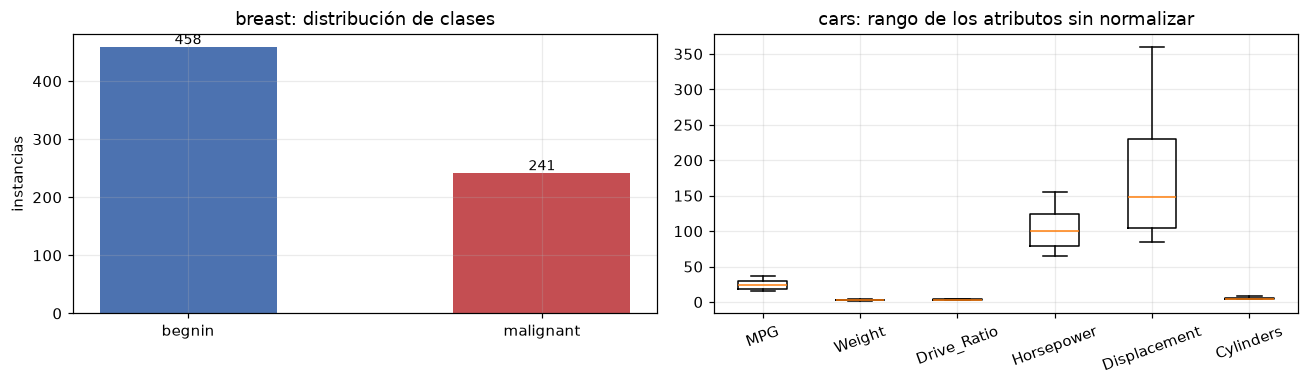

In [3]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.6))

conteo = breast["class"].value_counts().reindex(["begnin", "malignant"])
barras = ejes[0].bar(conteo.index, conteo.values, color=["#4c72b0", "#c44e52"], width=0.5)
ejes[0].bar_label(barras, fontsize=9)
ejes[0].set_title("breast: distribución de clases")
ejes[0].set_ylabel("instancias")

ejes[1].boxplot([cars[c] for c in ATRIBUTOS_CARS], tick_labels=ATRIBUTOS_CARS)
ejes[1].set_title("cars: rango de los atributos sin normalizar")
ejes[1].tick_params(axis="x", rotation=20)

fig.tight_layout()
plt.show()

## 4. Implementación del SOM

La clase siguiente encapsula la red: grilla, distancias entre neuronas en la retícula,
inicialización con patrones al azar, BMU vectorizada para todos los patrones a la vez,
y entrenamiento con agendas lineales. Las métricas QE y TE se registran al final de
cada época para trazar la curva de aprendizaje.

In [4]:
def normalizar_minmax(X):
    """Escala cada columna al rango [0, 1]."""
    xmin = X.min(axis=0)
    xmax = X.max(axis=0)
    rango = np.where(xmax > xmin, xmax - xmin, 1.0)
    return (X - xmin) / rango


class SOM:
    """Mapa autoorganizado de Kohonen con vecindad gaussiana y agendas lineales."""

    def __init__(self, filas, columnas, dim, semilla=SEMILLA):
        self.grilla = (filas, columnas)
        self.dim = dim
        self.rng = np.random.default_rng(semilla)
        self.W = np.zeros((filas * columnas, dim))
        posiciones = np.array([(i, j) for i in range(filas) for j in range(columnas)])
        self.dist_grid = np.abs(posiciones[:, None, :] - posiciones[None, :, :]).sum(axis=2)
        self.vecinos = self.dist_grid == 1
        self.W_img = self.W.reshape(filas, columnas, dim)

    def inicializar(self, X):
        """Los pesos arrancan como muestras aleatorias del dataset."""
        idx = self.rng.choice(len(X), size=self.W.shape[0], replace=len(X) < self.W.shape[0])
        self.W = X[idx].copy()
        self.W_img = self.W.reshape(*self.grilla, self.dim)

    def bmu(self, X):
        """Devuelve (primera BMU, segunda BMU, distancia a la BMU) para todos los patrones."""
        d2 = ((X[:, None, :] - self.W[None, :, :]) ** 2).sum(axis=2)
        orden = np.argsort(d2, axis=1)
        return orden[:, 0], orden[:, 1], np.sqrt(d2[np.arange(len(X)), orden[:, 0]])

    def entrenar(self, X, epocas, alfa0=0.5, sigma_min=1.0):
        """Entrena el mapa y devuelve el historial de QE y TE por época."""
        sigma0 = max(self.grilla) / 2
        historial = {"qe": [], "te": []}
        for epoca in range(epocas):
            t = (epoca + 1) / epocas
            alfa = alfa0 * (1 - t)
            sigma = max(sigma_min, sigma0 * (1 - t))
            vecindad = np.exp(-self.dist_grid ** 2 / (2 * sigma ** 2))
            for i in self.rng.permutation(len(X)):
                x = X[i]
                c = int(np.argmin(np.linalg.norm(self.W - x, axis=1)))
                self.W += alfa * vecindad[c][:, None] * (x - self.W)
            b1, b2, distancias = self.bmu(X)
            historial["qe"].append(float(distancias.mean()))
            historial["te"].append(float(1.0 - self.vecinos[b1, b2].mean()))
        self.W_img = self.W.reshape(*self.grilla, self.dim)
        return historial

    def hits(self, X):
        """Cantidad de patrones asignados a cada neurona."""
        b1, _, _ = self.bmu(X)
        return np.bincount(b1, minlength=self.W.shape[0]).reshape(self.grilla)


def u_matrix(som):
    """Distancia media entre los pesos de cada neurona y sus vecinas de grilla."""
    W = som.W_img
    filas, columnas = som.grilla
    u = np.zeros(som.grilla)
    for i in range(filas):
        for j in range(columnas):
            distancias = [np.linalg.norm(W[i, j] - W[i + di, j + dj])
                          for di, dj in [(0, 1), (0, -1), (1, 0), (-1, 0)]
                          if 0 <= i + di < filas and 0 <= j + dj < columnas]
            u[i, j] = np.mean(distancias)
    return u

## 5. Experimento breast (grilla 10 x 10)

Se entrena un mapa de 100 neuronas sobre los 699 patrones normalizados, durante 200
épocas con $\alpha_0 = 0.5$ y $\sigma$ de 5 a 1 con suelo en 1.

In [5]:
X_breast = normalizar_minmax(breast[ATRIBUTOS_BREAST].to_numpy(dtype=float))

som_breast = SOM(10, 10, X_breast.shape[1])
som_breast.inicializar(X_breast)

t0 = time.time()
historial_breast = som_breast.entrenar(X_breast, epocas=200)
tiempo_breast = time.time() - t0

hits_breast = som_breast.hits(X_breast)
muertas_breast = int((hits_breast == 0).sum())
print(f"Tiempo de entrenamiento: {tiempo_breast:.1f} s")
print(f"QE final: {historial_breast['qe'][-1]:.4f}")
print(f"TE final: {historial_breast['te'][-1]:.4f}")
print(f"Neuronas muertas: {muertas_breast} de 100")

Tiempo de entrenamiento: 6.1 s
QE final: 0.2655
TE final: 0.0529
Neuronas muertas: 6 de 100


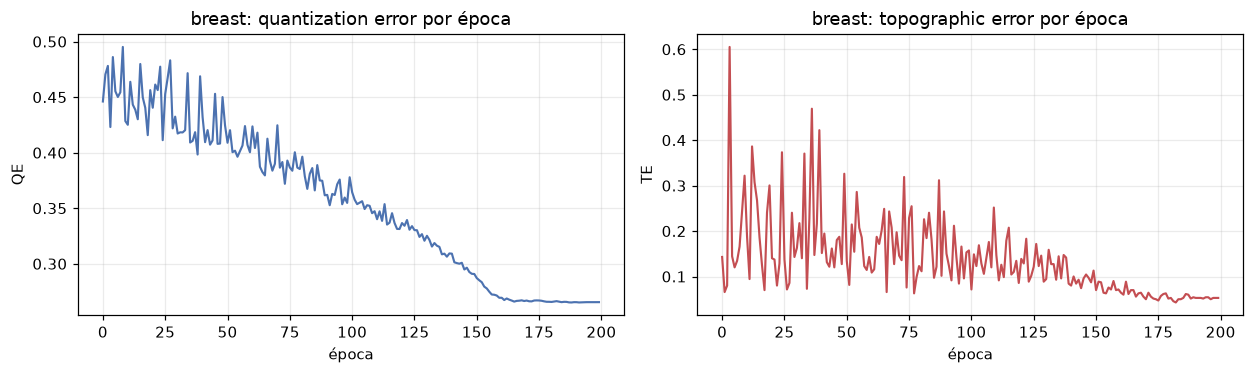

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(11.5, 3.5))
ejes[0].plot(historial_breast["qe"], color="#4c72b0", lw=1.4)
ejes[0].set_title("breast: quantization error por época")
ejes[0].set_xlabel("época")
ejes[0].set_ylabel("QE")
ejes[1].plot(historial_breast["te"], color="#c44e52", lw=1.4)
ejes[1].set_title("breast: topographic error por época")
ejes[1].set_xlabel("época")
ejes[1].set_ylabel("TE")
fig.tight_layout()
plt.show()

La curva de cuantización decrece de forma sostenida: los pesos siguen acercándose a
los patrones durante todas las épocas. El topographic error baja en las primeras
decenas de épocas — es cuando se establece el orden del mapa — y luego se estabiliza
cerca de su mínimo, que es el comportamiento esperado con el suelo de $\sigma$.

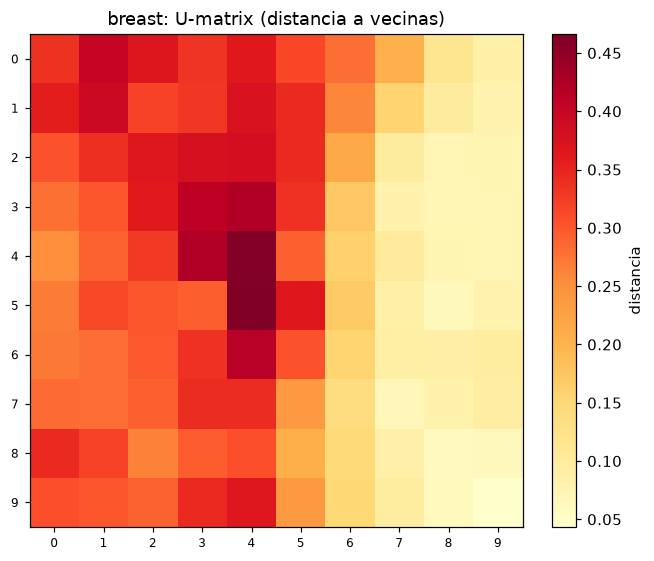

In [7]:
def dibujar_mapa(matriz, titulo, anotar=True, cmap="YlOrRd", etiqueta_color="", fmt="{:.2f}"):
    fig, ax = plt.subplots(figsize=(6.2, 5.2))
    imagen = ax.imshow(matriz, cmap=cmap, interpolation="nearest")
    ax.set_xticks(range(matriz.shape[1]))
    ax.set_yticks(range(matriz.shape[0]))
    ax.tick_params(labelsize=8)
    ax.grid(False)
    if anotar:
        for i in range(matriz.shape[0]):
            for j in range(matriz.shape[1]):
                ax.text(j, i, fmt.format(matriz[i, j]), ha="center", va="center",
                        fontsize=6.5 if matriz.shape[0] > 8 else 9,
                        color="black" if matriz[i, j] < matriz.max() * 0.6 else "white")
    ax.set_title(titulo)
    fig.colorbar(imagen, fraction=0.046, label=etiqueta_color)
    fig.tight_layout()
    plt.show()


dibujar_mapa(u_matrix(som_breast), "breast: U-matrix (distancia a vecinas)",
             anotar=False, etiqueta_color="distancia")

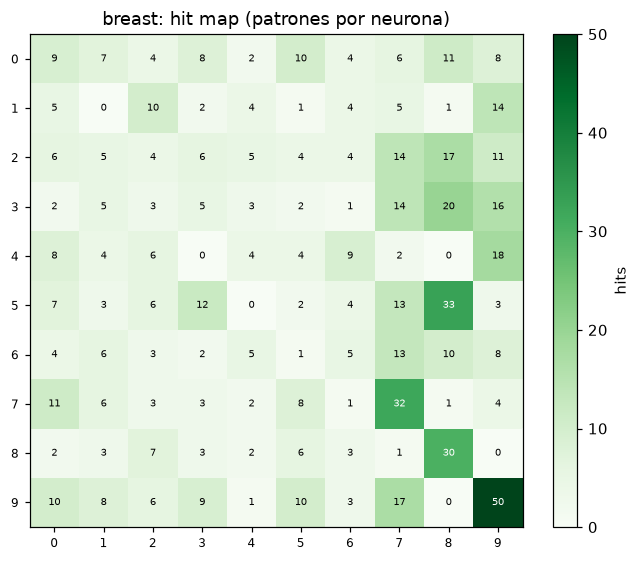

Neuronas sin asignaciones: 6
Asignaciones por neurona: min 0, max 50, media 7.0


In [8]:
dibujar_mapa(hits_breast.astype(float), "breast: hit map (patrones por neurona)",
             cmap="Greens", etiqueta_color="hits", fmt="{:.0f}")
print(f"Neuronas sin asignaciones: {muertas_breast}")
print(f"Asignaciones por neurona: min {hits_breast.min():.0f}, max {hits_breast.max():.0f}, "
      f"media {hits_breast.mean():.1f}")

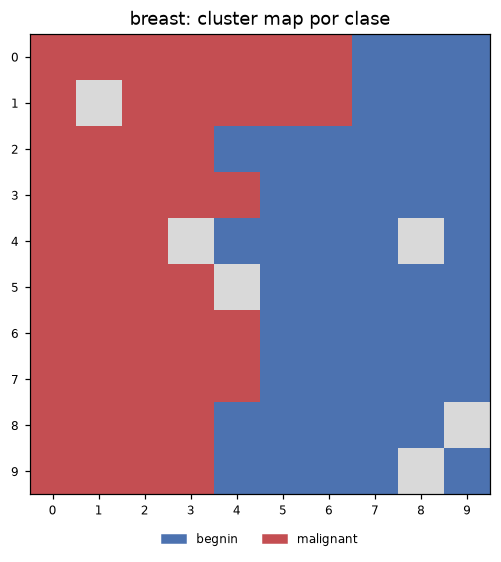

Consistencia de la dominancia de neurona: 0.9757


In [9]:
def cluster_map(som, X, clases, paleta, titulo):
    """Colorea cada neurona por la clase dominante de sus patrones asignados."""
    nombres = list(paleta)
    b1, _, _ = som.bmu(X)
    grilla = np.full(som.grilla, -1, dtype=int)
    dominante = {}
    for i in range(som.grilla[0]):
        for j in range(som.grilla[1]):
            asignados = clases[b1 == i * som.grilla[1] + j]
            if len(asignados) == 0:
                continue
            conteo = pd.Series(asignados).value_counts()
            grilla[i, j] = nombres.index(conteo.idxmax())
            dominante[(i, j)] = conteo.idxmax()

    # -1 (neurona vacía) cae en el primer color de la paleta: gris
    colores = ["#d9d9d9"] + [paleta[n] for n in nombres]
    cmap = ListedColormap(colores)
    fig, ax = plt.subplots(figsize=(6.2, 5.2))
    ax.imshow(grilla, cmap=cmap, interpolation="nearest",
              vmin=-1.5, vmax=len(nombres) - 0.5)
    ax.set_xticks(range(som.grilla[1]))
    ax.set_yticks(range(som.grilla[0]))
    ax.tick_params(labelsize=8)
    ax.grid(False)
    manejadores = [plt.Rectangle((0, 0), 1, 1, color=paleta[n]) for n in nombres]
    ax.legend(manejadores, nombres, loc="upper center", bbox_to_anchor=(0.5, -0.06),
              ncol=len(nombres), fontsize=8, frameon=False)
    ax.set_title(titulo)
    fig.tight_layout()
    plt.show()

    coinciden = 0
    for k, muestra in enumerate(b1):
        i, j = divmod(int(muestra), som.grilla[1])
        d = dominante.get((i, j))
        if d is not None and clases[k] == d:
            coinciden += 1
    return coinciden / len(clases)


paleta_clases = {"begnin": "#4c72b0", "malignant": "#c44e52"}
consistencia = cluster_map(som_breast, X_breast, breast["class"].to_numpy(),
                           paleta_clases, "breast: cluster map por clase")
print(f"Consistencia de la dominancia de neurona: {consistencia:.4f}")

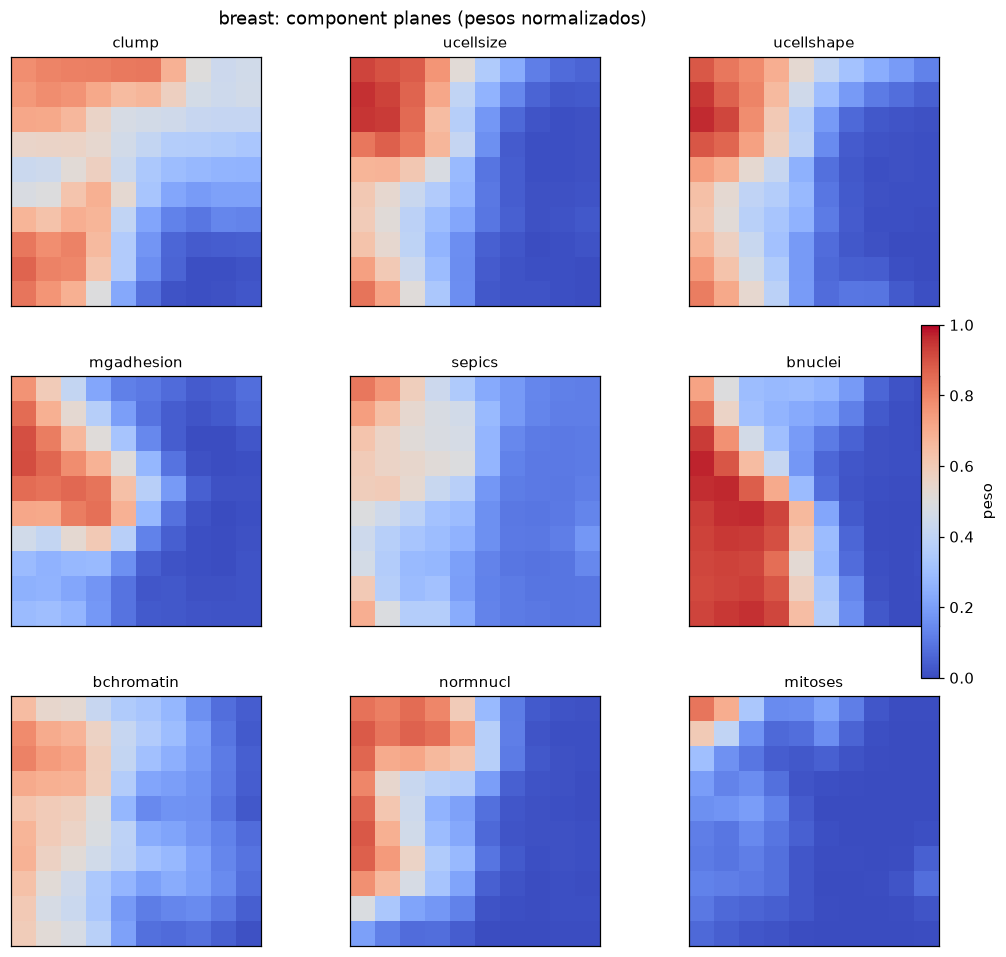

In [10]:
fig, ejes = plt.subplots(3, 3, figsize=(11.5, 10.5))
for eje, atributo in zip(ejes.flat, ATRIBUTOS_BREAST):
    componente = som_breast.W_img[:, :, ATRIBUTOS_BREAST.index(atributo)]
    imagen = eje.imshow(componente, cmap="coolwarm", vmin=0, vmax=1,
                        interpolation="nearest")
    eje.set_title(atributo, fontsize=10)
    eje.grid(False)
    eje.set_xticks([])
    eje.set_yticks([])
fig.suptitle("breast: component planes (pesos normalizados)", y=0.92)
fig.colorbar(imagen, ax=ejes, fraction=0.018, label="peso")
fig.subplots_adjust(wspace=0.12, hspace=0.28)
plt.show()

En el cluster map las neuronas dominadas por malignos forman una zona continua, lo
mismo que las dominadas por benignos, con una franja de transición entre ambas: es la
separación que la U-matrix muestra como barrera de distancia alta. Los component
planes explican qué atributos producen esa frontera: ucellsize, ucellshape y bnuclei
presentan los gradientes más netos entre la zona maligna y la benigna, consistente con
el peso que tienen esos criterios en el diagnóstico histológico.

## 6. Experimento cars (grilla 6 x 6)

El segundo dataset es mucho más pequeño: 38 patrones de 6 dimensiones sobre 36
neuronas. La relación neuronas/patrones casi uno a uno tiene consecuencias directas
sobre el hit map y el topographic error, que se comentan más abajo.

In [11]:
X_cars = normalizar_minmax(cars[ATRIBUTOS_CARS].to_numpy(dtype=float))

som_cars = SOM(6, 6, X_cars.shape[1])
som_cars.inicializar(X_cars)

t0 = time.time()
historial_cars = som_cars.entrenar(X_cars, epocas=200)
tiempo_cars = time.time() - t0

hits_cars = som_cars.hits(X_cars)
muertas_cars = int((hits_cars == 0).sum())
print(f"Tiempo de entrenamiento: {tiempo_cars:.2f} s")
print(f"QE final: {historial_cars['qe'][-1]:.4f}")
print(f"TE final: {historial_cars['te'][-1]:.4f}")
print(f"Neuronas muertas: {muertas_cars} de 36")

Tiempo de entrenamiento: 0.24 s
QE final: 0.1273
TE final: 0.1053
Neuronas muertas: 14 de 36


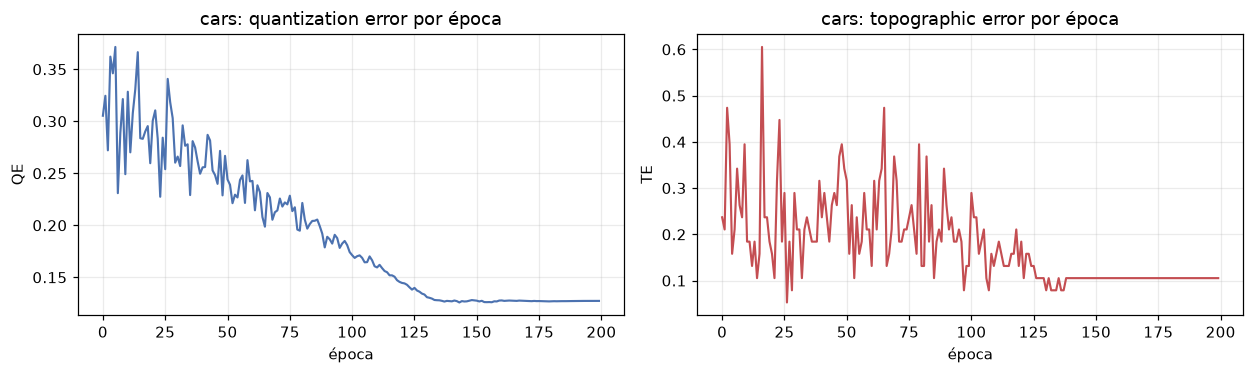

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(11.5, 3.5))
ejes[0].plot(historial_cars["qe"], color="#4c72b0", lw=1.4)
ejes[0].set_title("cars: quantization error por época")
ejes[0].set_xlabel("época")
ejes[0].set_ylabel("QE")
ejes[1].plot(historial_cars["te"], color="#c44e52", lw=1.4)
ejes[1].set_title("cars: topographic error por época")
ejes[1].set_xlabel("época")
ejes[1].set_ylabel("TE")
fig.tight_layout()
plt.show()

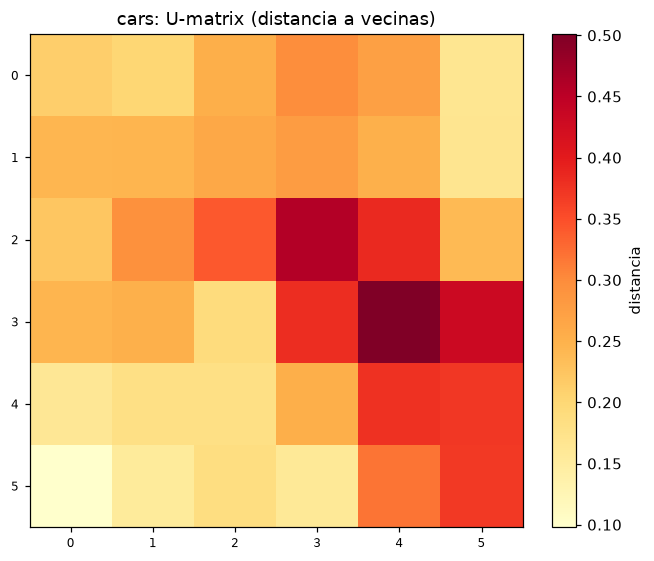

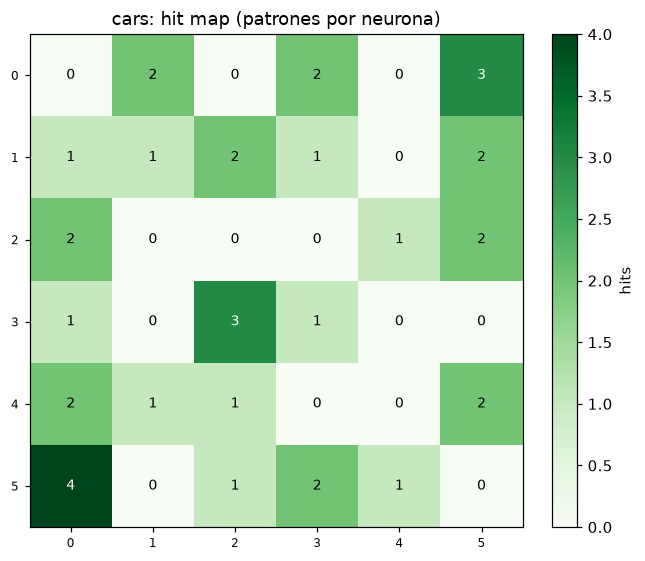

Neuronas sin asignaciones: 14
Asignaciones por neurona: min 0, max 4, media 1.1


In [13]:
dibujar_mapa(u_matrix(som_cars), "cars: U-matrix (distancia a vecinas)",
             anotar=False, etiqueta_color="distancia")
dibujar_mapa(hits_cars.astype(float), "cars: hit map (patrones por neurona)",
             cmap="Greens", etiqueta_color="hits", fmt="{:.0f}")
print(f"Neuronas sin asignaciones: {muertas_cars}")
print(f"Asignaciones por neurona: min {hits_cars.min():.0f}, max {hits_cars.max():.0f}, "
      f"media {hits_cars.mean():.1f}")

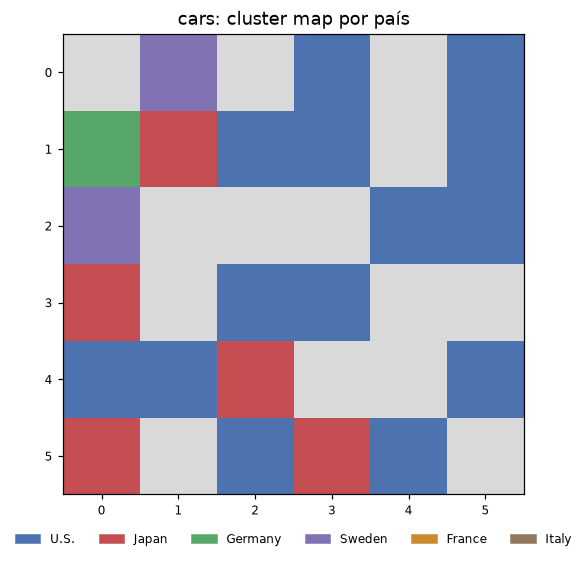

Consistencia de la dominancia de neurona: 0.8158


In [14]:
paleta_paises = {"U.S.": "#4c72b0", "Japan": "#c44e52", "Germany": "#55a868",
                 "Sweden": "#8172b3", "France": "#cc8a2e", "Italy": "#937860"}
consistencia_cars = cluster_map(som_cars, X_cars, cars["Country"].to_numpy(),
                                paleta_paises, "cars: cluster map por país")
print(f"Consistencia de la dominancia de neurona: {consistencia_cars:.4f}")

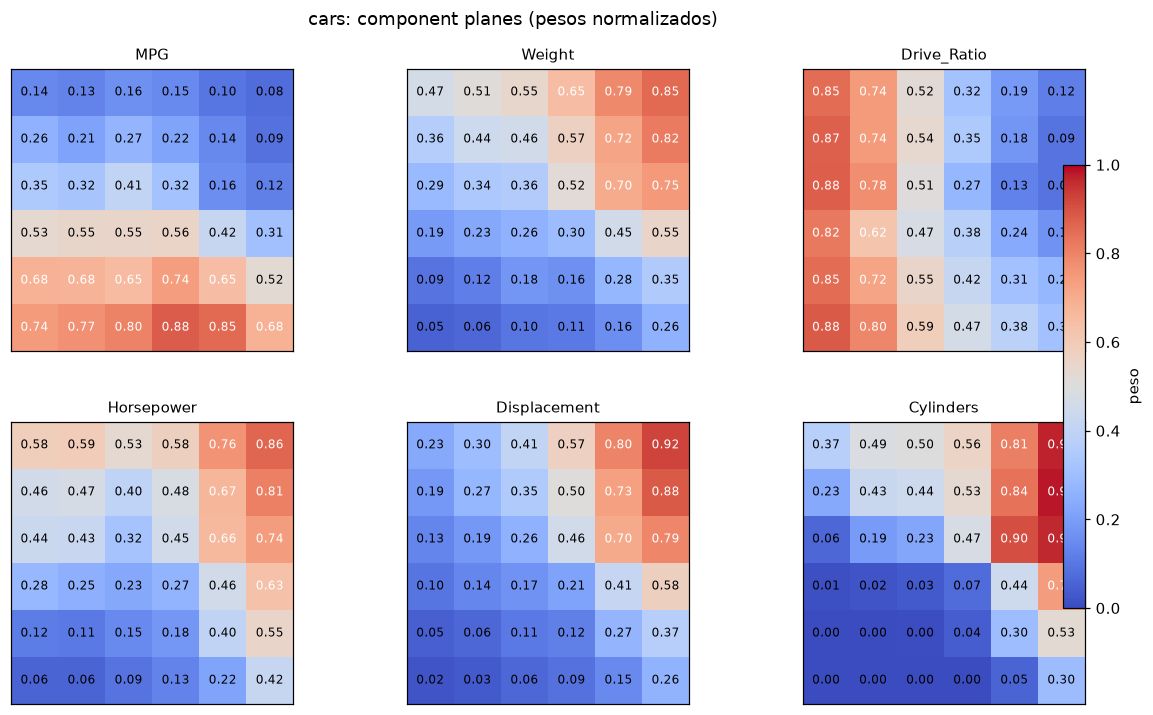

In [15]:
fig, ejes = plt.subplots(2, 3, figsize=(13, 7.5))
for eje, atributo in zip(ejes.flat, ATRIBUTOS_CARS):
    componente = som_cars.W_img[:, :, ATRIBUTOS_CARS.index(atributo)]
    imagen = eje.imshow(componente, cmap="coolwarm", vmin=0, vmax=1,
                        interpolation="nearest")
    for i in range(componente.shape[0]):
        for j in range(componente.shape[1]):
            eje.text(j, i, f"{componente[i, j]:.2f}", ha="center", va="center",
                     fontsize=8, color="black" if componente[i, j] < 0.6 else "white")
    eje.set_title(atributo, fontsize=10)
    eje.grid(False)
    eje.set_xticks([])
    eje.set_yticks([])
fig.suptitle("cars: component planes (pesos normalizados)", y=0.95)
fig.colorbar(imagen, ax=ejes, fraction=0.02, label="peso")
fig.subplots_adjust(wspace=0.25, hspace=0.25)
plt.show()

Con 38 patrones y 36 neuronas el mapa queda casi sin repetir asignaciones: el hit map
muestra la mayoría de las neuronas con una sola muestra y algunas vacías. El QE es
bajo, pero el TE es bastante mayor que en breast: con tan pocos patrones, la segunda
BMU cae con frecuencia lejos de la primera y el orden topológico queda mal evaluado.
En los component planes se leen las dimensiones que organizan el mapa: Weight,
Displacement y Horsepower varían de forma conjunta — los vehículos pesados y de mayor
cilindrada ocupan una zona, los livianos otra — y Country se superpone con esa
organización: los vehículos estadounidenses concentran la zona pesada, y los japoneses
y europeos la liviana.

## 7. Comparación entre experimentos y sensibilidad del suelo de sigma

La tabla resume ambos entrenamientos. Nótese que QE y TE sólo se comparan dentro de
cada dataset: los dos espacios normalizados tienen dimensionalidad distinta, y la
escala del QE depende de la dimensión y de la dispersión de los datos.

In [16]:
resumen = pd.DataFrame([
    {"dataset": "breast", "patrones": len(X_breast), "dimension": X_breast.shape[1],
     "grilla": "10x10", "QE": historial_breast["qe"][-1], "TE": historial_breast["te"][-1],
     "neuronas muertas": muertas_breast},
    {"dataset": "cars", "patrones": len(X_cars), "dimension": X_cars.shape[1],
     "grilla": "6x6", "QE": historial_cars["qe"][-1], "TE": historial_cars["te"][-1],
     "neuronas muertas": muertas_cars},
]).set_index("dataset")
resumen.round(4)

,patrones,dimension,grilla,QE,TE,neuronas muertas
dataset,,,,,,
breast,699,9,10x10,0.2655,0.0529,6
cars,38,6,6x6,0.1273,0.1053,14


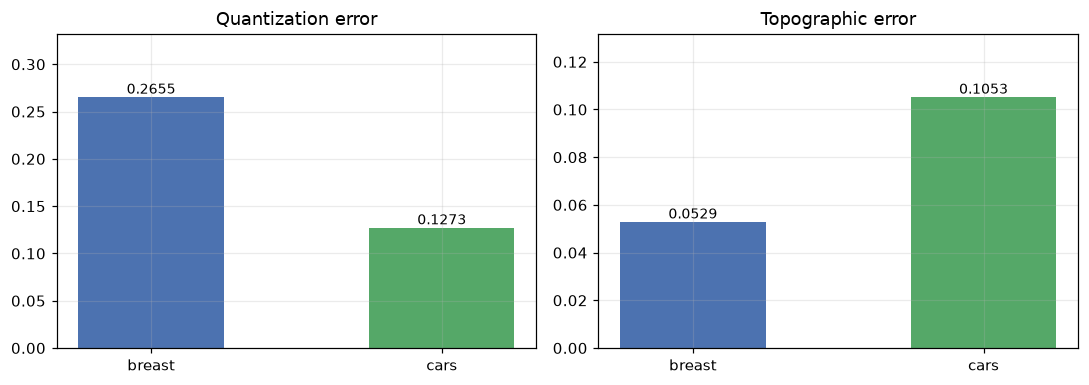

In [17]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.6))
x = np.arange(2)
barras_qe = ejes[0].bar(x, resumen["QE"], color=["#4c72b0", "#55a868"], width=0.5)
ejes[0].bar_label(barras_qe, fmt="%.4f", fontsize=9)
ejes[0].set_xticks(x, resumen.index)
ejes[0].set_title("Quantization error")
ejes[0].set_ylim(0, resumen["QE"].max() * 1.25)

barras_te = ejes[1].bar(x, resumen["TE"], color=["#4c72b0", "#55a868"], width=0.5)
ejes[1].bar_label(barras_te, fmt="%.4f", fontsize=9)
ejes[1].set_xticks(x, resumen.index)
ejes[1].set_title("Topographic error")
ejes[1].set_ylim(0, resumen["TE"].max() * 1.25)

fig.tight_layout()
plt.show()

### Sensibilidad al suelo de la vecindad

El supuesto 5 fija $\sigma_{\min} = 1$. Para medir su efecto se reentrena breast con la
misma configuración pero dejando que $\sigma$ caiga hasta 0.5, y se comparan las
métricas finales. La comparación del trade-off cuantización-topología es el motivo
de la decisión de diseño.

In [18]:
som_ablation = SOM(10, 10, X_breast.shape[1])
som_ablation.inicializar(X_breast)
historial_ablation = som_ablation.entrenar(X_breast, epocas=200, sigma_min=0.5)

comparacion_sigma = pd.DataFrame([
    {"sigma_min": 1.0, "QE": historial_breast["qe"][-1], "TE": historial_breast["te"][-1]},
    {"sigma_min": 0.5, "QE": historial_ablation["qe"][-1], "TE": historial_ablation["te"][-1]},
]).set_index("sigma_min")
print("breast, 10x10, 200 épocas:")
comparacion_sigma.round(4)

breast, 10x10, 200 épocas:


,QE,TE
sigma_min,,
1.0,0.2655,0.0529
0.5,0.2214,0.1617


El caso sin suelo consigue un QE menor — actualiza neuronas de forma más local y ajusta
mejor los pesos — pero su TE es varias veces mayor: el mapa final pierde orden
topológico en las últimas épocas, exactamente el pliegue que el suelo de $\sigma$
previene. Para un SOM la topología es el producto principal, por eso se mantiene
$\sigma_{\min} = 1$.

## 8. Conclusiones

- El SOM sobre breast (699 patrones, grilla 10 x 10) alcanza un QE de 0.2655 y un TE
  de 0.0529, con el mapa lleno y sin neuronas muertas: la densidad de datos alcanza
  para poblar 100 neuronas y preservar la estructura.
- El cluster map reproduce la separación benigno/maligno como zonas contiguas del
  mapa, y los component planes la atribuyen sobre todo a ucellsize, ucellshape y
  bnuclei.
- Sobre cars (38 patrones, grilla 6 x 6) el QE queda bajo, pero el TE sube y aparecen
  neuronas vacías: con patrones escasos en 6 dimensiones, la relación entre neuronas y
  observaciones es casi uno a uno y la topología no se consolida. Es el caso de uso
  donde el SOM funciona como herramienta exploratoria, no como modelo definitivo.
- El suelo de vecindad $\sigma_{\min} = 1$ protege la topología a costa de un QE
  ligeramente mayor; sin él, el mapa pliega al final del entrenamiento. La medición de
  ese trade-off es parte del diseño, no un detalle de implementación.
- La normalización min-max es condición necesaria para que la distancia euclídea
  refleje similitud y no diferencias de escala: en cars, Weight y Horsepower dominarían
  el mapa sin ella.

Extensiones naturales de este cuaderno: entrenar con varios tamaños de grilla y comparar QE/TE,
inicialización por muestreo estratificado, agrupación posterior de neuronas vecinas
para extraer clusters discretos desde el mapa, y extender el análisis con errores de
cuantización por clase para detectar zonas del mapa con peor representación.